# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


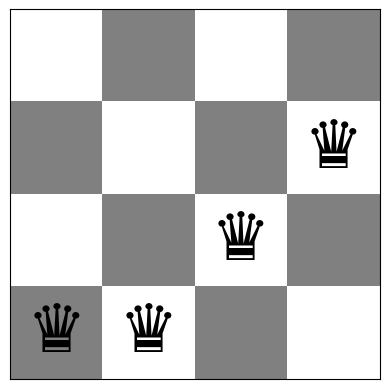

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


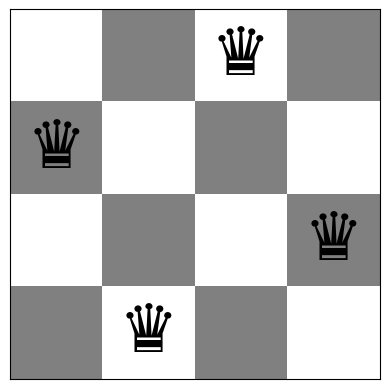

In [4]:
board = [1,3,0,2]
show_board(board)

## Bài 5: Biểu diễn bài toán n quân hậu

**Biểu diễn trạng thái.** Mỗi cột có đúng một quân hậu; `board[i]` là chỉ số hàng của quân hậu ở cột `i` ($0 \le$ `board[i]` $< n$). Ví dụ `[1, 3, 0, 2]` nghĩa là quân ở cột 0 nằm hàng 1, cột 1 nằm hàng 3, ... Vì mỗi cột chỉ có một quân nên **không bao giờ có xung đột theo cột**, chỉ cần xét hàng và đường chéo.

- `random_board(n)`: sinh ngẫu nhiên một hàng cho mỗi cột (các quân có thể trùng hàng).
- `show_board(board)`: vẽ bàn cờ và in số xung đột.
- `conflicts(board)`: hàm mục tiêu $h$.

**Hàm mục tiêu.** $h(\text{board})$ là số cặp quân hậu tấn công nhau (cùng hàng hoặc cùng đường chéo):

$$h(\text{board}) = \sum_{0 \le i < j < n} \Big[\ \text{board}[i] = \text{board}[j] \ \ \lor\ \ |\text{board}[i] - \text{board}[j]| = j - i\ \Big]$$

Hai quân ở cột $i, j$ nằm trên cùng một đường chéo khi khoảng cách hàng bằng khoảng cách cột. Mỗi cặp chỉ được đếm một lần ($i < j$).

**Cách `conflicts()` tính nhanh.** Thay vì duyệt $O(n^2)$ cặp, hàm đếm số quân trên mỗi hàng (`board[i]`), mỗi đường chéo chính (`i + board[i]`) và mỗi đường chéo phụ (`i - board[i] + n`, cộng $n$ để chỉ số không âm). Một đường có $k$ quân sinh ra $\binom{k}{2}$ cặp tấn công, nên $h = \sum \binom{k}{2}$ trên tất cả các đường, với độ phức tạp $O(n)$.

Ô dưới đây cài `attacking_pairs()` theo đúng công thức định nghĩa (duyệt từng cặp) để **kiểm tra chéo** với `conflicts()`, hiển thị bàn cờ n = 4 và n = 8 kèm $h$, và kiểm tra rằng $h = 0$ khi và chỉ khi không có cặp quân hậu nào tấn công nhau.

n = 4: 1000 bàn ngẫu nhiên, conflicts() khớp attacking_pairs() ở mọi bàn; 6 bàn có h = 0
n = 8: 1000 bàn ngẫu nhiên, conflicts() khớp attacking_pairs() ở mọi bàn; 0 bàn có h = 0

Bàn ngẫu nhiên n = 4: [3, 1, 3, 3] -> h = 4, số cặp tấn công (đếm trực tiếp) = 4
Board with 4 conflicts.


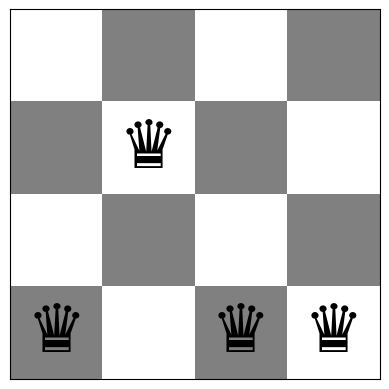


Bàn ngẫu nhiên n = 8: [1, 6, 7, 1, 6, 5, 2, 0] -> h = 5, số cặp tấn công (đếm trực tiếp) = 5
Board with 5 conflicts.


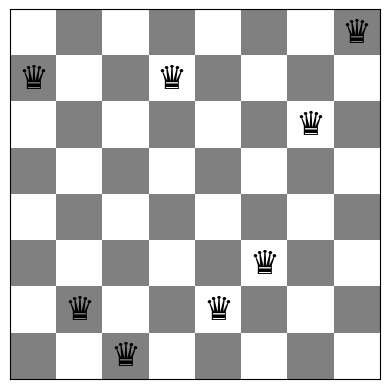


Nghiệm mẫu n = 4: [1, 3, 0, 2] -> h = 0, số cặp tấn công = 0
Board with 0 conflicts.


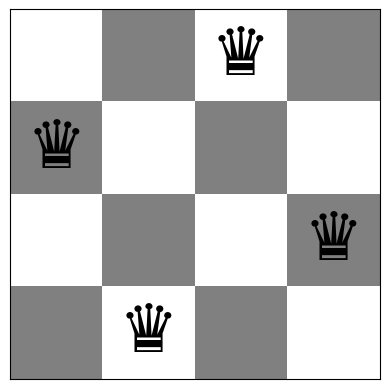


Nghiệm mẫu n = 8: [0, 4, 7, 5, 2, 6, 1, 3] -> h = 0, số cặp tấn công = 0
Board with 0 conflicts.


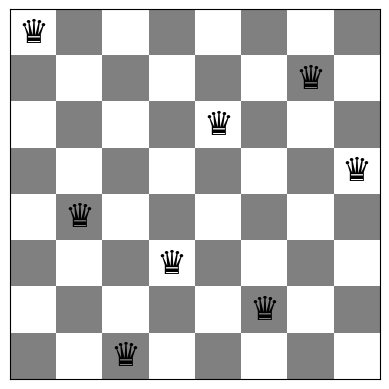

In [5]:
def attacking_pairs(board):
    """Đếm trực tiếp số cặp quân hậu tấn công nhau bằng cách duyệt mọi cặp (i, j), i < j.
    Đây là cách tính h(board) 'đúng định nghĩa', dùng để kiểm tra lại hàm conflicts()."""
    n = len(board)
    cnt = 0
    for i in range(n):
        for j in range(i + 1, n):
            same_row = board[i] == board[j]
            same_diag = abs(int(board[i]) - int(board[j])) == j - i
            if same_row or same_diag:
                cnt += 1
    return cnt


# 1) Kiểm tra conflicts() == attacking_pairs() trên nhiều bàn cờ ngẫu nhiên
np.random.seed(2024)
for n in (4, 8):
    boards = [random_board(n) for _ in range(1000)]
    assert all(conflicts(b) == attacking_pairs(b) for b in boards)
    n_zero = sum(conflicts(b) == 0 for b in boards)
    print(f"n = {n}: 1000 bàn ngẫu nhiên, conflicts() khớp attacking_pairs() ở mọi bàn; "
          f"{n_zero} bàn có h = 0")

# 2) Một bàn 4x4 và một bàn 8x8 ngẫu nhiên, hiển thị kèm h(board)
for n, fs in ((4, 48), (8, 24)):
    b = random_board(n)
    print(f"\nBàn ngẫu nhiên n = {n}: {b.tolist()} -> h = {conflicts(b)}, "
          f"số cặp tấn công (đếm trực tiếp) = {attacking_pairs(b)}")
    show_board(b, fontsize=fs)

# 3) Bàn đã biết là nghiệm: h = 0 và đúng là không có cặp nào tấn công nhau
for b in ([1, 3, 0, 2], [0, 4, 7, 5, 2, 6, 1, 3]):
    print(f"\nNghiệm mẫu n = {len(b)}: {b} -> h = {conflicts(b)}, "
          f"số cặp tấn công = {attacking_pairs(b)}")
    show_board(b, fontsize=48 if len(b) == 4 else 24)

**Nhận xét Bài 5:**

- Trên 1000 bàn ngẫu nhiên cho mỗi kích thước n = 4 và n = 8, `conflicts()` cho kết quả **trùng khớp hoàn toàn** với cách đếm trực tiếp theo từng cặp. Vì vậy $h(\text{board})$ đúng bằng số cặp quân hậu tấn công nhau.
- Do $h$ là tổng các số không âm (mỗi cặp tấn công đóng góp đúng 1), nên $h = 0 \iff$ không có cặp nào tấn công nhau, tức bàn cờ là nghiệm. Hai nghiệm mẫu `[1, 3, 0, 2]` (n = 4) và `[0, 4, 7, 5, 2, 6, 1, 3]` (n = 8) đều cho $h = 0$ và 0 cặp tấn công.
- Bàn ngẫu nhiên hầu như không phải nghiệm: n = 4 chỉ có 2 nghiệm trên $4^4 = 256$ bàn (≈ 0,8%, khớp với 6/1000 bàn đo được), còn n = 8 chỉ có 92 nghiệm trên $8^8 \approx 16{,}8$ triệu bàn nên 1000 bàn ngẫu nhiên không bàn nào có $h = 0$. Đây là lý do cần các thuật toán tìm kiếm cục bộ ở các Task sau.

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

### Cách làm

**Láng giềng (local move):** chọn 1 cột `col` và đưa quân hậu của cột đó sang một hàng khác `row != board[col]`. Với bàn $n \times n$ có $n(n-1)$ láng giềng (n=8 → 56).

**Steepest-ascent:** ở mỗi bước
1. Duyệt *toàn bộ* $n(n-1)$ láng giềng, tính `conflicts()` của từng cái.
2. Lấy giá trị nhỏ nhất `best_h`. Nếu `best_h < h` hiện tại thì đi theo nước đó (nếu nhiều nước bằng nhau thì bốc ngẫu nhiên một nước trong số đó).
3. Nếu không có láng giềng nào *tốt hơn hẳn* thì dừng: đây là **cực trị cục bộ** (hoặc plateau, xem phần phân tích bên dưới).

**Thống kê ghi lại** (dùng chung cho mọi thuật toán, hàm trả về `(board, info)`):
- `conflicts`: số xung đột cuối `h`
- `steps`: số lần thật sự đổi bàn cờ
- `evals`: số lần gọi hàm mục tiêu `conflicts()` (đây là chi phí tính toán chính, không phụ thuộc máy)
- `history`: giá trị `h` sau mỗi bước, dùng để vẽ đồ thị hội tụ

Ta chỉ chấp nhận nước đi **cải thiện hẳn** (`<`), nên chắc chắn dừng sau hữu hạn bước vì `h` là số nguyên không âm và giảm ngặt. `max_steps` chỉ là chốt an toàn.

=== Steepest-ascent HC (n = 8) ===
Bàn cờ ban đầu       : [7, 3, 6, 5, 4, 4, 0, 1]  (h = 9)
Bàn cờ cuối          : [7, 3, 7, 2, 4, 6, 0, 5]
Xung đột cuối (h)    : 1
Số bước              : 4
Số lần đánh giá h    : 281
Trường hợp dừng      : mắc kẹt ở PLATEAU (có láng giềng bằng h, không có láng giềng tốt hơn)
Board with 1 conflicts.


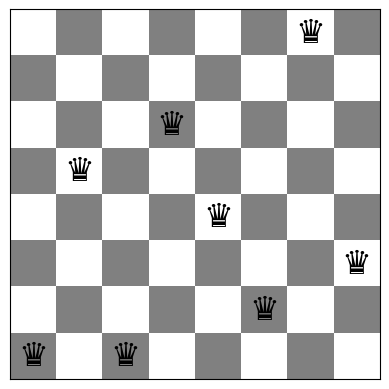

In [6]:
def steepest_ascent(board, max_steps=1000):
    """Steepest-ascent hill climbing: xét hết láng giềng, đi nước tốt nhất."""
    board = np.array(board).copy()          # không sửa bàn cờ gốc của người gọi
    n = len(board)
    h = conflicts(board)
    evals, steps, history = 1, 0, [h]       # evals=1 vì đã tính h của trạng thái đầu

    while h > 0 and steps < max_steps:
        best_h, best_moves = h, []          # chỉ quan tâm nước cải thiện hơn h
        for col in range(n):
            old = board[col]
            for row in range(n):
                if row == old:
                    continue
                board[col] = row            # thử nước đi
                nh = conflicts(board); evals += 1
                if nh < best_h:             # tốt hơn mọi nước đã thấy -> làm lại danh sách
                    best_h, best_moves = nh, [(col, row)]
                elif nh == best_h and best_moves:
                    best_moves.append((col, row))   # hòa nước tốt nhất
            board[col] = old                # hoàn tác trước khi thử cột khác

        if not best_moves:                  # không có láng giềng nào tốt hơn -> kẹt
            break
        col, row = best_moves[np.random.randint(len(best_moves))]
        board[col] = row
        h = best_h; steps += 1; history.append(h)

    return board, dict(conflicts=h, steps=steps, evals=evals, history=history)


def stuck_type(board):
    """Phân loại trạng thái lúc thuật toán dừng bằng cách quét toàn bộ láng giềng.
    Chỉ dùng để báo cáo, KHÔNG cộng vào evals của thuật toán."""
    board = np.array(board).copy()
    n, h = len(board), conflicts(board)
    if h == 0:
        return "đạt nghiệm tối ưu (h = 0)"
    has_equal = False
    for col in range(n):
        old = board[col]
        for row in range(n):
            if row == old:
                continue
            board[col] = row
            nh = conflicts(board)
            if nh < h:                      # vẫn còn nước cải thiện -> thuật toán dừng sớm
                return "chưa kẹt: vẫn còn nước cải thiện nhưng đã chạm điều kiện dừng"
            has_equal |= (nh == h)
        board[col] = old
    if has_equal:
        return "mắc kẹt ở PLATEAU (có láng giềng bằng h, không có láng giềng tốt hơn)"
    return "mắc kẹt ở CỰC TRỊ CỤC BỘ (mọi láng giềng đều tệ hơn)"


def report(name, start, end, info):
    """In kết quả một lượt chạy theo cùng một định dạng cho Task 1-3."""
    print(f"=== {name} (n = {len(start)}) ===")
    print(f"Bàn cờ ban đầu       : {np.asarray(start).tolist()}  (h = {conflicts(start)})")
    print(f"Bàn cờ cuối          : {np.asarray(end).tolist()}")
    print(f"Xung đột cuối (h)    : {info['conflicts']}")
    print(f"Số bước              : {info['steps']}")
    print(f"Số lần đánh giá h    : {info['evals']}")
    print(f"Trường hợp dừng      : {stuck_type(end)}")


# Ví dụ một lượt chạy trên bàn 8x8 (cùng bàn khởi tạo cho Task 1-3 để dễ so sánh)
np.random.seed(1234)
start = random_board(8)
end, info = steepest_ascent(start)
report("Steepest-ascent HC", start, end, info)
show_board(end, fontsize=24)


**Nhận xét Task 1:** từ bàn cờ h = 9, Steepest-ascent HC giảm h rất nhanh trong **4 bước** nhưng dừng ở **h = 1** sau **281 lần đánh giá** = (4 bước + 1 lần quét cuối) × 56 láng giềng + 1. Trạng thái cuối là **plateau**: có láng giềng cũng có h = 1 nhưng không có láng giềng nào tốt hơn, và vì thuật toán chỉ nhận nước cải thiện hẳn (`<`) nên nó đứng yên. Đây là hạn chế điển hình của hill climbing; Task 4 (Random Restart) và Task 5 (Simulated Annealing) xử lý vấn đề này.

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

### Cách làm

Giống Task 1 ở chỗ vẫn phải tính hết $n(n-1)$ láng giềng, nhưng thay vì chọn nước *tốt nhất* thì **gom tất cả nước cải thiện** (`nh < h`) rồi **bốc ngẫu nhiên một nước** trong đó. Nếu danh sách rỗng thì dừng (hết nước cải thiện).

Khác biệt so với steepest: nó không luôn đi nước dốc nhất nên đường đi ngẫu nhiên hơn và có thể cần nhiều bước hơn, nhưng **chi phí mỗi bước vẫn là $n(n-1)$ lần đánh giá**. Vì vậy thuật toán này "kém hiệu quả" (inefficient) như đề nói.

=== Inefficient Stochastic HC (n = 8) ===
Bàn cờ ban đầu       : [7, 3, 6, 5, 4, 4, 0, 1]  (h = 9)
Bàn cờ cuối          : [7, 2, 0, 5, 1, 4, 6, 3]
Xung đột cuối (h)    : 0
Số bước              : 6
Số lần đánh giá h    : 337
Trường hợp dừng      : đạt nghiệm tối ưu (h = 0)
Board with 0 conflicts.


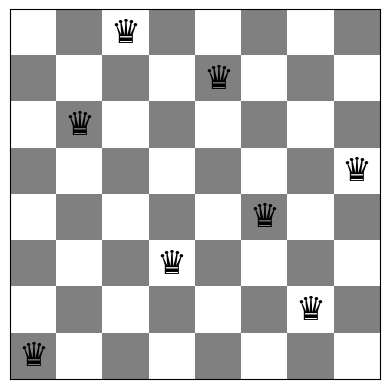

In [7]:
def ineff_stochastic(board, max_steps=1000):
    """Stochastic hill climbing 'kém hiệu quả': tính hết láng giềng, chọn ngẫu nhiên trong các nước cải thiện."""
    board = np.array(board).copy()
    n = len(board)
    h = conflicts(board)
    evals, steps, history = 1, 0, [h]

    while h > 0 and steps < max_steps:
        better = []                          # mọi nước đi làm h giảm ngặt
        for col in range(n):
            old = board[col]
            for row in range(n):
                if row == old:
                    continue
                board[col] = row
                nh = conflicts(board); evals += 1
                if nh < h:
                    better.append((col, row, nh))
            board[col] = old

        if not better:                       # không còn nước cải thiện -> kẹt
            break
        col, row, nh = better[np.random.randint(len(better))]   # bốc ngẫu nhiên
        board[col] = row
        h = nh; steps += 1; history.append(h)

    return board, dict(conflicts=h, steps=steps, evals=evals, history=history)


np.random.seed(1234)
start = random_board(8)
end, info = ineff_stochastic(start)
report("Inefficient Stochastic HC", start, end, info)
show_board(end, fontsize=24)


**Nhận xét Task 2:** từ cùng bàn khởi tạo (h = 9), Inefficient Stochastic HC đi **6 bước** (Steepest chỉ đi 4) vì không phải lúc nào cũng chọn nước dốc nhất, và tốn **337 lần đánh giá** (mỗi bước tốn 56 lần cho n = 8). Ở lượt này nó may mắn đạt **h = 0**: chọn ngẫu nhiên giúp đi theo một hướng khác và tránh được plateau mà Steepest gặp phải. Đây chỉ là kết quả một lượt, không có nghĩa thuật toán này luôn tốt hơn.

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

### Cách làm

Mỗi vòng lặp chỉ sinh **một** láng giềng ngẫu nhiên (chọn cột ngẫu nhiên, chọn hàng mới ngẫu nhiên khác hàng cũ), tính `h` đúng **1 lần đánh giá**, và chấp nhận nếu tốt hơn hẳn; nếu không thì hoàn tác.

**Điều kiện dừng (tránh lặp vô hạn).** Ta không bao giờ liệt kê hết láng giềng nên không *chứng minh* được là đã kẹt. Cách thực tế: dừng khi **`patience` lần thử liên tiếp đều không cải thiện** (hoặc khi `h = 0`). Chọn `patience` thế nào?

- Có $N = n(n-1)$ láng giềng và ta bốc *có hoàn lại*. Xác suất một láng giềng cụ thể chưa được thử sau $x$ lần là $(1 - 1/N)^x \approx e^{-x/N}$.
- Chọn $x = N \ln N$ thì xác suất đó là $\approx 1/N$, nghĩa là sau $x$ lần thử, kỳ vọng chỉ còn khoảng **1 láng giềng** (trong $N$) chưa được xem. Nếu có ít nhất một nước cải thiện thì xác suất bỏ sót tất cả chúng còn nhỏ hơn nữa.
- Vậy `patience = ceil(N ln N)`: n=4 → 30, n=8 → 226. Giá trị tăng theo kích thước bàn cờ như đề gợi ý.

Ngoài ra có thêm chốt `max_iters` để chắc chắn dừng.

patience: n=4 -> 30 | n=8 -> 226
=== Efficient Stochastic HC (n = 8) ===
Bàn cờ ban đầu       : [7, 3, 6, 5, 4, 4, 0, 1]  (h = 9)
Bàn cờ cuối          : [1, 3, 5, 7, 4, 6, 0, 2]
Xung đột cuối (h)    : 1
Số bước              : 6
Số lần đánh giá h    : 277
Trường hợp dừng      : mắc kẹt ở PLATEAU (có láng giềng bằng h, không có láng giềng tốt hơn)
Board with 1 conflicts.


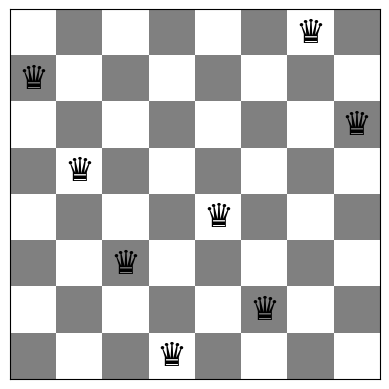

In [8]:
def default_patience(n):
    """x = ceil(N ln N) với N = n(n-1) là số láng giềng (xem giải thích ở trên)."""
    N = n * (n - 1)
    return int(math.ceil(N * math.log(N)))

def efficient_stochastic(board, patience=None, max_iters=100000):
    """First-choice / stochastic hill climbing: mỗi vòng chỉ thử 1 láng giềng ngẫu nhiên."""
    board = np.array(board).copy()
    n = len(board)
    if patience is None:
        patience = default_patience(n)
    h = conflicts(board)
    evals, steps, fails, it, history = 1, 0, 0, 0, [h]

    while h > 0 and fails < patience and it < max_iters:
        it += 1
        col = np.random.randint(n)
        row = np.random.randint(n - 1)       # bốc trong n-1 hàng còn lại...
        if row >= board[col]:
            row += 1                          # ...rồi bỏ qua hàng hiện tại
        old = board[col]
        board[col] = row
        nh = conflicts(board); evals += 1     # chỉ 1 lần đánh giá cho mỗi láng giềng
        if nh < h:                            # cải thiện -> nhận, reset bộ đếm thất bại
            h = nh; steps += 1; fails = 0
        else:                                 # không cải thiện -> hoàn tác
            board[col] = old; fails += 1
        history.append(h)

    return board, dict(conflicts=h, steps=steps, evals=evals, history=history)


print("patience: n=4 ->", default_patience(4), "| n=8 ->", default_patience(8))
np.random.seed(1234)
start = random_board(8)
end, info = efficient_stochastic(start)
report("Efficient Stochastic HC", start, end, info)
show_board(end, fontsize=24)


**Nhận xét Task 3:** cùng bàn khởi tạo (h = 9), Efficient Stochastic HC dừng ở **h = 1** sau 6 bước cải thiện với **277 lần đánh giá**. Chỉ hơn Steepest (281) một chút, vì trong đó có 226 lần thử thất bại liên tiếp (`patience`) mới dừng. Trạng thái cuối là **plateau**, đúng là bị kẹt chứ không phải dừng sớm vì hết `patience` khi vẫn còn nước cải thiện. Mỗi lần thử chỉ tốn 1 lần đánh giá, nên khi số láng giềng lớn thì nó tiết kiệm hơn nhiều so với Task 1 và Task 2.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

### Cách làm

`random_restart(algo, n)` lặp tối đa **100 lần**: mỗi lần tạo một bàn cờ ngẫu nhiên mới, chạy `algo` (một trong ba biến thể hill climbing), giữ lại bàn cờ tốt nhất đã thấy và **dừng ngay khi tìm được `h = 0`**. Chi phí (`evals`, `steps`) được **cộng dồn qua mọi lần restart**, vì đó mới là chi phí thật để có được lời giải.

Ta chạy quy trình này 100 lần độc lập cho mỗi thuật toán (mỗi lần với chuỗi bàn cờ khởi tạo khác nhau) để thống kê số lần thành công và chi phí trung bình.

In [9]:
import time
import pandas as pd

def evaluate(solver, n, runs=100, seed=0):
    """Chạy solver(n) -> (board, info) `runs` lần, trả về thống kê trung bình."""
    np.random.seed(seed)
    hs, steps, evals, times, restarts = [], [], [], [], []
    for _ in range(runs):
        t0 = time.perf_counter()
        b, info = solver(n)
        times.append(time.perf_counter() - t0)
        hs.append(info['conflicts']); steps.append(info['steps']); evals.append(info['evals'])
        restarts.append(info.get('restarts', 1))
    hs = np.array(hs)
    return {"Thành công (%)": 100 * np.mean(hs == 0), "h cuối TB": hs.mean(),
            "Số bước TB": np.mean(steps), "Số lần đánh giá TB": np.mean(evals),
            "Thời gian TB (ms)": 1000 * np.mean(times), "Số lần restart TB": np.mean(restarts)}

hill_climbers = {"Steepest": steepest_ascent, "Ineff. Stochastic": ineff_stochastic, "Efficient Stochastic": efficient_stochastic}


def random_restart(algo, n, max_restarts=100):
    """Chạy lại `algo` từ bàn cờ ngẫu nhiên mới tối đa max_restarts lần, dừng khi h = 0."""
    total_evals, total_steps, restarts = 0, 0, 0
    best_board, best_h = None, float("inf")
    for _ in range(max_restarts):
        b, info = algo(random_board(n))
        restarts += 1
        total_evals += info['evals']; total_steps += info['steps']
        if info['conflicts'] < best_h:
            best_board, best_h = b, info['conflicts']
        if best_h == 0:
            break
    return best_board, dict(conflicts=best_h, restarts=restarts, evals=total_evals, steps=total_steps)


rr_rows = {}
for n in (4, 8):
    for name, f in hill_climbers.items():
        rr_rows[(n, name + " + Restart")] = evaluate(lambda n, f=f: random_restart(f, n), n)
rr_table = pd.DataFrame(rr_rows).T
rr_table.index.names = ["n", "Thuật toán"]
rr_table[["Thành công (%)", "Số lần restart TB", "Số lần đánh giá TB", "Thời gian TB (ms)"]].round(2)

Thành công (%)  Số lần restart TB  \
n Thuật toán                                                          
4 Steepest + Restart                       100.0               2.10   
  Ineff. Stochastic + Restart              100.0               2.92   
  Efficient Stochastic + Restart           100.0               3.68   
8 Steepest + Restart                       100.0               8.08   
  Ineff. Stochastic + Restart              100.0               6.98   
  Efficient Stochastic + Restart           100.0               8.12   

                                  Số lần đánh giá TB  Thời gian TB (ms)  
n Thuật toán                                                             
4 Steepest + Restart                           54.42               0.31  
  Ineff. Stochastic + Restart                  90.04               0.49  
  Efficient Stochastic + Restart              119.34               1.08  
8 Steepest + Restart                         1829.20              19.39  
  Ineff. Stochastic + Restart                2285.06              27.90  
  Efficient Stochastic + Restart             2152.44              32.23

**Nhận xét:**

- Với tối đa 100 lần restart, cả ba biến thể đều đạt **100% thành công** ở n = 4 và n = 8. Không lượt nào phải dùng hết 100 lần restart.
- Mỗi lần restart là một phép thử độc lập, nên số lần restart trung bình ≈ $1/p$, với $p$ là xác suất một lượt đơn tìm được nghiệm. Từ bảng ở n = 8 ta ước lượng được $p \approx 1/8{,}08 \approx 12\%$ (Steepest), $1/6{,}98 \approx 14\%$ (Ineff. Stochastic) và $1/8{,}12 \approx 12\%$ (Efficient Stochastic). Nghĩa là một lượt hill climbing đơn lẻ ở n = 8 thất bại khoảng 86–88% số lần, phù hợp với ví dụ ở Task 1–3, nơi 2/3 thuật toán bị kẹt ở plateau với h = 1.
- Cái giá là chi phí: một lượt đơn ở Task 1–3 chỉ tốn khoảng 280–340 lần đánh giá, còn có restart thì cần khoảng **1830–2290** lần mỗi lời giải ở n = 8, tức gấp khoảng 7–8 lần. Ở n = 4 bàn cờ nhỏ, p cao hơn nên chỉ cần khoảng 2–4 lần restart.
- Restart không "học" gì từ các lần trước. Nó chỉ bỏ trạng thái bị kẹt và thử lại từ đầu cho đến khi gặp một bàn khởi tạo tốt. Simulated Annealing (Task 5) thì thoát kẹt ngay trong cùng một lượt chạy.


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

### Cách làm

Simulated Annealing (SA) giống Efficient Stochastic HC (mỗi vòng thử 1 láng giềng ngẫu nhiên), nhưng quy tắc chấp nhận khác: gọi $\Delta h = h_{mới} - h_{cũ}$ thì
- nếu $\Delta h \le 0$: luôn nhận;
- nếu $\Delta h > 0$ (tệ hơn): nhận với xác suất $p = e^{-\Delta h / T}$.

Nhiệt độ $T$ cao thì dễ nhận nước tệ (khám phá nhiều), $T$ thấp thì gần như chỉ nhận nước tốt (khai thác). $T$ giảm dần theo **lịch làm nguội** (annealing schedule). Ví dụ với $T = 1$, nước tệ hơn 1 xung đột được nhận với xác suất $e^{-1} \approx 37\%$, còn khi $T = 0{,}1$ chỉ còn $e^{-10} \approx 0{,}005\%$.

**Hai họ lịch làm nguội được thử** (T0 = 2 vì $\Delta h$ thường cỡ 1-3):
- *Hình học:* $T_k = T_0 \cdot \alpha^k$, thử $\alpha = 0{,}99$ (nguội nhanh) và $\alpha = 0{,}999$ (nguội chậm).
- *Tuyến tính:* $T_k = T_0 (1 - k/K)$ với $K = 5000$.

**Điều kiện dừng:** `h = 0` hoặc hết `max_iters = 5000` vòng. Hàm luôn nhớ *bàn cờ tốt nhất từng thấy* (`best`), vì trạng thái cuối của SA có thể tệ hơn do đã nhận nước đi xấu. Báo cáo phân biệt rõ: thành công = `h = 0`, còn "nghiệm tốt nhất" = `h` nhỏ nhất đã gặp.

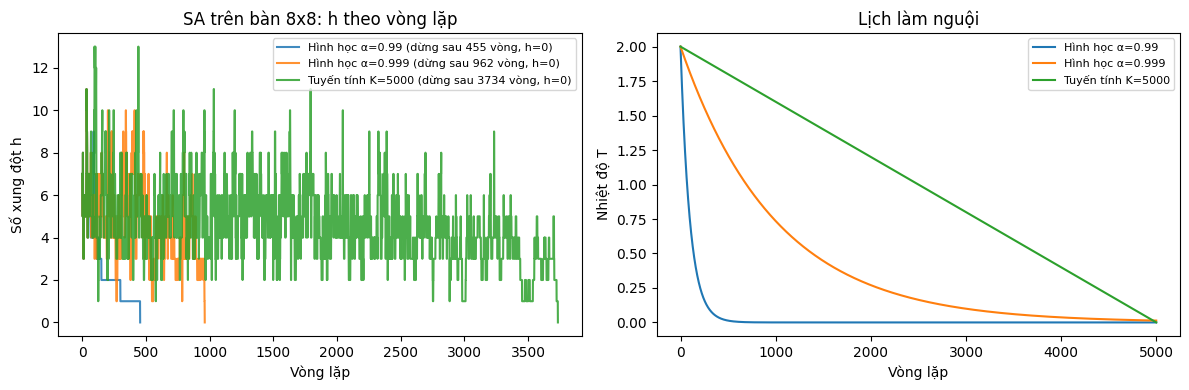

In [10]:
def geometric(T0=2.0, alpha=0.99):
    return lambda k: T0 * alpha ** k

def linear(T0=2.0, K=5000):
    return lambda k: max(T0 * (1 - k / K), 1e-9)   # tránh chia cho 0

def simulated_annealing(board, schedule, max_iters=5000):
    """SA: nhận nước tệ hơn với xác suất exp(-dh/T), T lấy từ lịch làm nguội schedule(k)."""
    board = np.array(board).copy()
    n = len(board)
    h = conflicts(board)
    evals, history = 1, [h]
    best_board, best_h = board.copy(), h

    for k in range(max_iters):
        if h == 0:
            break
        T = schedule(k)
        col = np.random.randint(n)
        row = np.random.randint(n - 1)
        if row >= board[col]:
            row += 1
        old = board[col]
        board[col] = row
        nh = conflicts(board); evals += 1
        dh = nh - h
        if dh <= 0 or np.random.rand() < math.exp(-dh / T):   # quy tắc Metropolis
            h = nh
            if h < best_h:
                best_board, best_h = board.copy(), h
        else:
            board[col] = old
        history.append(h)

    return best_board, dict(conflicts=best_h, final_conflicts=h, steps=len(history) - 1,
                            evals=evals, history=history)


schedules = {"Hình học α=0.99": geometric(2.0, 0.99),
             "Hình học α=0.999": geometric(2.0, 0.999),
             "Tuyến tính K=5000": linear(2.0, 5000)}

# Vẽ quá trình tìm kiếm: cùng một bàn cờ khởi tạo n=8 cho cả ba lịch
np.random.seed(7)
start = random_board(8)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, sched in schedules.items():
    np.random.seed(11)                                  # cùng dãy ngẫu nhiên để so sánh công bằng
    _, info = simulated_annealing(start, sched)
    axes[0].plot(info['history'], label=f"{name} (dừng sau {info['steps']} vòng, h={info['conflicts']})", alpha=0.85)
axes[0].set_xlabel("Vòng lặp"); axes[0].set_ylabel("Số xung đột h"); axes[0].set_title("SA trên bàn 8x8: h theo vòng lặp")
axes[0].legend(fontsize=8)

ks = np.arange(5000)
for name, sched in schedules.items():
    axes[1].plot(ks, [sched(k) for k in ks], label=name)
axes[1].set_xlabel("Vòng lặp"); axes[1].set_ylabel("Nhiệt độ T"); axes[1].set_title("Lịch làm nguội"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Một lượt chạy chỉ cho cảm nhận về hình dạng, nên để so sánh các lịch làm nguội ta chạy mỗi lịch **100 lần** trên bàn 4x4 và 8x8:

In [11]:
sa_rows = {}
for n in (4, 8):
    for name, sched in schedules.items():
        sa_rows[(n, name)] = evaluate(lambda n, s=sched: simulated_annealing(random_board(n), s), n)
sa_table = pd.DataFrame(sa_rows).T
sa_table.index.names = ["n", "Lịch làm nguội"]
sa_table[["Thành công (%)", "h cuối TB", "Số lần đánh giá TB", "Thời gian TB (ms)"]].round(2)

Thành công (%)  h cuối TB  Số lần đánh giá TB  \
n Lịch làm nguội                                                     
4 Hình học α=0.99             100.0       0.00               70.20   
  Hình học α=0.999            100.0       0.00               79.64   
  Tuyến tính K=5000           100.0       0.00               80.87   
8 Hình học α=0.99              98.0       0.02              750.51   
  Hình học α=0.999             99.0       0.01             1679.01   
  Tuyến tính K=5000            97.0       0.03             3209.36   

                     Thời gian TB (ms)  
n Lịch làm nguội                        
4 Hình học α=0.99                 0.70  
  Hình học α=0.999                0.77  
  Tuyến tính K=5000               0.77  
8 Hình học α=0.99                10.90  
  Hình học α=0.999               22.28  
  Tuyến tính K=5000              42.92

**Nhận xét về lịch làm nguội (hình trên và bảng):**

- Ở đầu quá trình $T$ cao nên `h` dao động mạnh, có lúc tăng lên 10-13: SA chấp nhận nhiều nước đi tệ để *khám phá*. Khi $T$ giảm, đường `h` đi xuống và ổn định dần, rồi chạm 0. Đây là khác biệt rõ nhất so với hill climbing, vốn chỉ đi xuống và dừng.
- **Nguội nhanh (α = 0,99)**: tốn ít vòng nhất (≈ 750 lần đánh giá ở n = 8, thành công 98%) vì sau khoảng 300 vòng $T$ đã rất thấp và thuật toán chuyển sang "khai thác". Rủi ro là nếu chưa tìm được vùng tốt trước khi nguội thì dễ kẹt.
- **Nguội chậm (α = 0,999)**: thành công 99% nhưng tốn gấp đôi (≈ 1680 lần đánh giá), nhờ có nhiều thời gian khám phá hơn.
- **Tuyến tính**: tốn nhiều nhất (≈ 3200 lần đánh giá) và thành công thấp nhất (97%). Một giải thích hợp lý là $T$ giảm đều nên phần lớn thời gian vẫn ở mức cao (T ≈ 1 ở vòng 2500), `h` tiếp tục dao động rộng rãi, chỉ khi $T$ gần 0 mới hội tụ.
- Bài học: lịch làm nguội là *siêu tham số* quan trọng, đánh đổi giữa chi phí và xác suất thành công; với n = 8, nguội hình học khá nhanh là lựa chọn tốt. Sự chênh lệch 97-99% giữa các lịch nằm trong dao động của 100 lượt nên cần thận trọng khi kết luận về độ chính xác, còn khác biệt về chi phí (750 so với 3200) thì rõ ràng.

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

### Cách làm

- **Số lượt:** mỗi thuật toán chạy **200 lượt** cho mỗi kích thước n = 4 và n = 8 (`RUNS = 200`).
- **Bàn khởi tạo:** 200 bàn được sinh **một lần** với `seed = 42` và dùng **chung cho cả 4 thuật toán**, nên khác biệt giữa các thuật toán không đến từ việc bốc phải bàn dễ hay bàn khó.
- **Thiết lập từng thuật toán:**
  - Steepest và Ineff. Stochastic dừng khi không còn nước cải thiện.
  - Efficient Stochastic dừng sau `patience = ⌈N ln N⌉` lần thử thất bại liên tiếp.
  - Simulated Annealing dùng lịch hình học $T_0 = 2$, $\alpha = 0{,}99$ (lịch tốt nhất ở Task 5) và tối đa 5000 vòng.
  - Đây là các lượt **đơn, không restart**. Random Restart đã được đánh giá riêng ở Task 4.
- **Cách đo:**
  - *Avg. Run time*: thời gian trung bình một lượt, đo bằng `time.perf_counter()` (ms).
  - *Avg. number of conflicts*: $h$ cuối trung bình. Với SA là $h$ tốt nhất đã gặp, xem Task 5.
  - *% optimal*: tỷ lệ lượt có $h = 0$.

`run_many()` lưu kết quả **từng lượt** (gồm $h$, số lần đánh giá, thời gian, bàn cờ cuối). Các bảng và biểu đồ bên dưới đều tính lại từ dữ liệu này.

In [12]:
RUNS = 200                                  # số lượt chạy cho mỗi (thuật toán, n)
SA_SCHEDULE = geometric(2.0, 0.99)          # lịch làm nguội tốt nhất ở Task 5

algorithms = {
    "Steepest asc. HC":        steepest_ascent,
    "Ineff. Stochastic HC":    ineff_stochastic,
    "Efficient Stochastic HC": efficient_stochastic,
    "Simulated Annealing":     lambda b: simulated_annealing(b, SA_SCHEDULE),
}

def run_many(algo, boards):
    """Chạy algo trên từng bàn khởi tạo, ghi lại kết quả của MỖI lượt (để tính trung bình sau)."""
    rows = []
    for b in boards:
        t0 = time.perf_counter()
        end, info = algo(b)
        rows.append(dict(h=info['conflicts'], evals=info['evals'],
                         time_ms=1000 * (time.perf_counter() - t0), board=end))
    return pd.DataFrame(rows)

# Mọi thuật toán dùng CHUNG một bộ RUNS bàn khởi tạo cho mỗi n -> so sánh công bằng
np.random.seed(42)
start_boards = {n: [random_board(n) for _ in range(RUNS)] for n in (4, 8)}

runs = {}                                   # runs[(tên, n)] = DataFrame kết quả từng lượt
for n in (4, 8):
    for name, algo in algorithms.items():
        np.random.seed(0)                   # cùng dãy ngẫu nhiên bên trong thuật toán
        runs[(name, n)] = run_many(algo, start_boards[n])

task6_table = pd.DataFrame(
    [{"Algorithm": name, "Board size": n,
      "Avg. Run time (ms)": df.time_ms.mean(),
      "Avg. number of conflicts": df.h.mean(),
      "% of runs ending in optimal solution": 100 * (df.h == 0).mean()}
     for (name, n), df in sorted(runs.items(), key=lambda kv: kv[0][1])])
task6_table.round(3)

,Algorithm,Board size,Avg. Run time (ms),Avg. number of conflicts,% of runs ending in optimal solution
0,Steepest asc. HC,4,0.141,0.645,40.0
1,Ineff. Stochastic HC,4,0.158,0.815,33.5
2,Efficient Stochastic HC,4,0.280,0.850,29.0
3,Simulated Annealing,4,0.607,0.000,100.0
4,Steepest asc. HC,8,1.963,1.235,15.0
5,Ineff. Stochastic HC,8,2.808,1.300,12.5
6,Efficient Stochastic HC,8,3.820,1.375,12.0
7,Simulated Annealing,8,12.040,0.040,96.0


| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      | 0.14 ms       | 0.645                              | 40 |
| Ineff. Stochastic HC |     4      | 0.16 ms       | 0.815                              | 33.5 |
| Efficient Stochastic HC |     4   | 0.28 ms       | 0.85                              | 29 |
| Simulated Annealing  |     4      | 0.61 ms       | 0                              | 100 |
| Steepest asc. HC     |     8      | 1.95 ms       | 1.235                              | 15 |
| Ineff. Stochastic HC |     8      | 2.82 ms       | 1.3                              | 12.5 |
| Efficient Stochastic HC |     8   | 3.32 ms       | 1.375                              | 12 |
| Simulated Annealing  |     8      | 12.01 ms       | 0.04                              | 96 |

*(200 lượt mỗi dòng, thời gian tính bằng ms. Thời gian chạy phụ thuộc máy nên có thể lệch một chút khi chạy lại; $h$ và tỷ lệ thành công không đổi vì đã cố định seed.)*

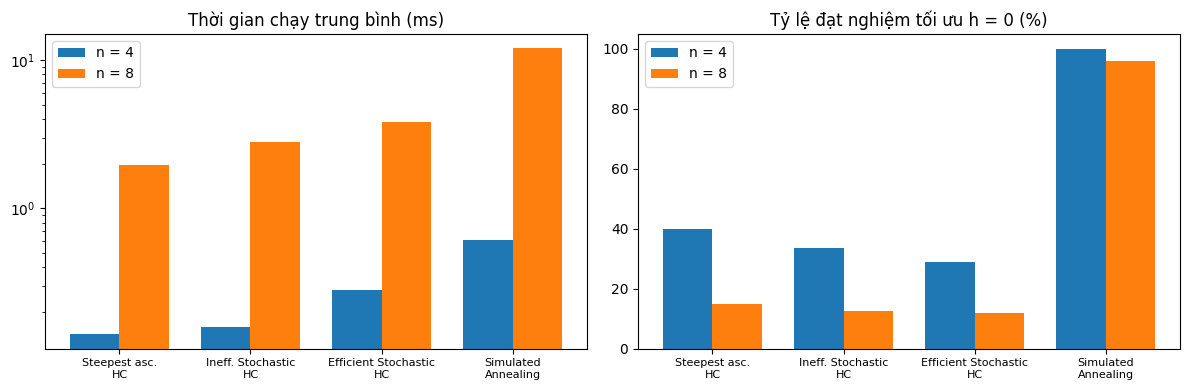

In [13]:
# Biểu đồ so sánh thời gian chạy và tỷ lệ thành công (200 lượt mỗi thiết lập)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
names = list(algorithms)
x = np.arange(len(names)); w = 0.38
for k, n in enumerate((4, 8)):
    sub = task6_table[task6_table["Board size"] == n].set_index("Algorithm").loc[names]
    axes[0].bar(x + (k - 0.5) * w, sub["Avg. Run time (ms)"], w, label=f"n = {n}")
    axes[1].bar(x + (k - 0.5) * w, sub["% of runs ending in optimal solution"], w, label=f"n = {n}")
for ax, title in zip(axes, ["Thời gian chạy trung bình (ms)", "Tỷ lệ đạt nghiệm tối ưu h = 0 (%)"]):
    ax.set_xticks(x); ax.set_xticklabels([s.replace(" HC", "\nHC").replace(" Annealing", "\nAnnealing") for s in names], fontsize=8)
    ax.set_title(title); ax.legend()
axes[0].set_yscale("log")
plt.tight_layout(); plt.show()

**Nhận xét so sánh (bảng và biểu đồ):**

- **Tỷ lệ thành công:** SA vượt trội hẳn, với **100%** ở n = 4 và **96%** ở n = 8. Ba biến thể hill climbing chỉ đạt 29–40% ở n = 4 và giảm còn 12–15% ở n = 8. Lý do là HC chỉ nhận nước cải thiện nên phần lớn lượt dừng ở plateau với $h$ = 1–2. Vì vậy $h$ cuối trung bình của HC là khoảng 1.235–1.375 ở n = 8, còn SA chỉ 0.04.
- **Thời gian:** một lượt HC rất nhanh (khoảng 1.95–3.32 ms ở n = 8) vì dừng sớm. SA chậm hơn nhiều (12.01 ms) vì chạy đến khi $h = 0$ hoặc hết vòng lặp. Thời gian của SA "mua" được tỷ lệ thành công cao hơn rất nhiều.
- **Giữa ba biến thể HC:**
  - Steepest có tỷ lệ thành công cao nhất và chạy nhanh nhất ở n = 8. Mỗi bước nó đi nước tốt nhất nên cần ít bước, và mỗi bước chỉ quét 56 láng giềng.
  - Efficient Stochastic tuy chỉ đánh giá 1 láng giềng mỗi lần, nhưng ở n = 8 nó phải chờ đủ `patience = 226` lần thất bại mới dừng (nhiều hơn 56 láng giềng). Ngoài ra mỗi vòng có thêm chi phí sinh số ngẫu nhiên của Python. Do đó ở bàn nhỏ nó **chưa** nhanh hơn. Lợi thế của nó chỉ thấy rõ khi số láng giềng lớn (xem phần mở rộng theo n).
- **So sánh công bằng hơn:** nếu tính chi phí để *có một nghiệm*, HC cần trung bình khoảng $1/p$ lượt (Task 4). Ví dụ Steepest + Restart ở n = 8 tốn khoảng 1600–1800 lần đánh giá cho mỗi nghiệm, cùng bậc với một lượt SA.

#### Số liệu riêng cho bảng 4.2 (file hướng dẫn Lab04)

Bảng 4.2 trong file Lab04 có cột **"Xung đột / COUNT"** và dòng **Random Restart**, mà bảng của Task 6 ở trên không có. Ô dưới đây tính các số đó vào **một biến riêng `xung_dot_42`** (dict) và chỉ in ra dạng chữ, **không** gộp vào bảng Task 6 và **không** vẽ biểu đồ.

- **Xung đột TB** = $h$ cuối trung bình qua 200 lượt. Với SA là $h$ tốt nhất đã gặp.
- **Số lần đánh giá TB** = số lần gọi `conflicts()`. Đây là "COUNT" của n-Queens và **không cùng đơn vị** với COUNT (số nút) của bài tô màu đồ thị.
- **Nguồn dữ liệu:**
  - Các dòng HC và SA dùng lại đúng 200 lượt của Task 6.
  - Dòng Random Restart dùng Steepest HC, tối đa 100 lần khởi động lại, chạy 200 lượt. Mỗi lần khởi động lại tự sinh bàn ngẫu nhiên mới.

In [14]:
# Biến riêng cho cột "Xung đột / COUNT" của bảng 4.2 trong file Lab04 (KHÔNG đưa vào bảng Task 6, KHÔNG vẽ)
# - Xung đột TB   : h cuối trung bình qua RUNS lượt (với SA là h tốt nhất đã gặp)
# - Số lần đánh giá: số lần gọi conflicts() trung bình (chi phí tính toán, khác COUNT của bài tô màu)
np.random.seed(0)
rr_runs = run_many(lambda b: random_restart(steepest_ascent, len(b)), start_boards[8])  # Random Restart n = 8

lab42_rows = {
    "n-Queens | n = 4 | Steepest HC":                   runs[("Steepest asc. HC", 4)],
    "n-Queens | n = 8 | Stochastic HC (Inefficient)":   runs[("Ineff. Stochastic HC", 8)],
    "n-Queens | n = 8 | Stochastic HC (Efficient)":     runs[("Efficient Stochastic HC", 8)],
    "n-Queens | n = 8 | Random Restart (Steepest)":     rr_runs,
    "n-Queens | n = 8 | Simulated Annealing (α=0.99)":  runs[("Simulated Annealing", 8)],
}
xung_dot_42 = {k: dict(luot=len(df), thanh_cong_pct=100 * (df.h == 0).mean(),
                       xung_dot_tb=df.h.mean(), so_lan_danh_gia_tb=df.evals.mean(),
                       thoi_gian_tb_s=df.time_ms.mean() / 1000)
               for k, df in lab42_rows.items()}

for k, v in xung_dot_42.items():
    print(f"{k:<50} lượt = {v['luot']} | thành công = {v['thanh_cong_pct']:.1f}% | "
          f"xung đột TB = {v['xung_dot_tb']:.3f} | số lần đánh giá TB = {v['so_lan_danh_gia_tb']:.1f} | "
          f"thời gian TB = {v['thoi_gian_tb_s']:.5f} s")

n-Queens | n = 4 | Steepest HC                     lượt = 200 | thành công = 40.0% | xung đột TB = 0.645 | số lần đánh giá TB = 27.2 | thời gian TB = 0.00014 s
n-Queens | n = 8 | Stochastic HC (Inefficient)     lượt = 200 | thành công = 12.5% | xung đột TB = 1.300 | số lần đánh giá TB = 326.9 | thời gian TB = 0.00281 s
n-Queens | n = 8 | Stochastic HC (Efficient)       lượt = 200 | thành công = 12.0% | xung đột TB = 1.375 | số lần đánh giá TB = 262.7 | thời gian TB = 0.00382 s
n-Queens | n = 8 | Random Restart (Steepest)       lượt = 200 | thành công = 100.0% | xung đột TB = 0.000 | số lần đánh giá TB = 1631.7 | thời gian TB = 0.01410 s
n-Queens | n = 8 | Simulated Annealing (α=0.99)    lượt = 200 | thành công = 96.0% | xung đột TB = 0.040 | số lần đánh giá TB = 925.8 | thời gian TB = 0.01204 s


*Điều kiện thí nghiệm để ghi vào bảng 4.2:*
- 200 lượt mỗi dòng; bàn khởi tạo sinh với `seed = 42`; seed bên trong thuật toán là 0.
- Tiêu chí dừng:
  - HC: hết nước cải thiện hoặc hết `patience`.
  - Random Restart: $h = 0$ hoặc đủ 100 lần khởi động lại.
  - SA: $h = 0$ hoặc 5000 vòng.
- Mọi giá trị là trung bình cộng qua các lượt.

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

Ô dưới đây chạy cả 4 thuật toán trên **cùng một bàn 8×8** (h ban đầu = 11) và vẽ $h$ theo vòng lặp.

- **Hình trái:** trục hoành là vòng lặp. Với Steepest/Ineff. đó là một bước đi; với Efficient/SA đó là một lần thử láng giềng.
- **Hình phải:** cùng dữ liệu, nhưng trục hoành là **số lần đánh giá hàm mục tiêu**. Mỗi bước của Steepest/Ineff. tốn $n(n-1) = 56$ lần, nên hình này so sánh chi phí thật.

Sau đó, bảng thống kê phân loại trạng thái dừng của cả 200 lượt n = 8 ở Task 6 bằng `stuck_type()` (Task 1):
- **plateau**: không có láng giềng tốt hơn nhưng có láng giềng bằng $h$;
- **cực trị cục bộ**: mọi láng giềng đều tệ hơn;
- **dừng sớm**: vẫn còn nước cải thiện nhưng đã chạm điều kiện dừng.

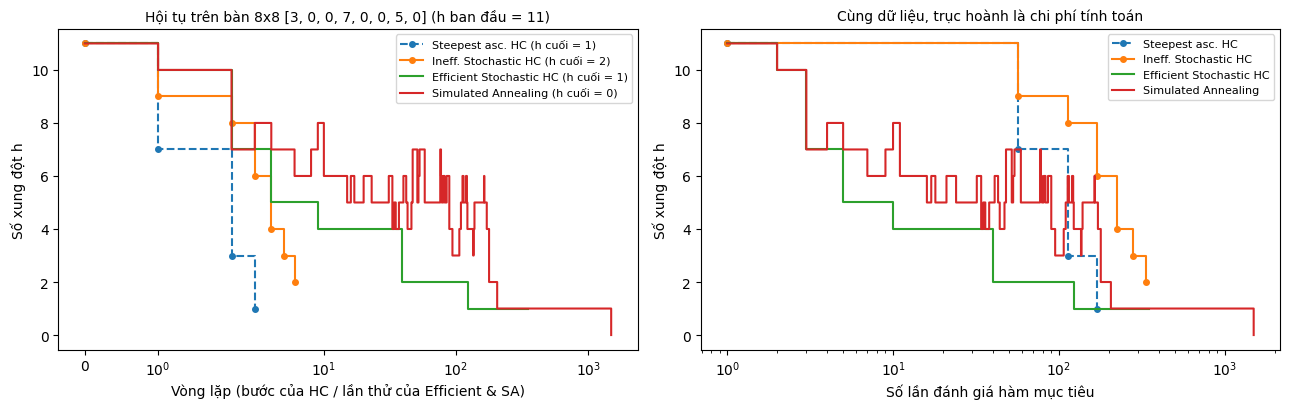

,h = 0,plateau,cực trị cục bộ,dừng sớm
"Thuật toán (n = 8, 200 lượt)",,,,
Steepest asc. HC,30,169,1,0
Ineff. Stochastic HC,25,175,0,0
Efficient Stochastic HC,24,175,0,1
Simulated Annealing,192,4,3,1


In [15]:
# Một lượt đại diện của mỗi thuật toán trên CÙNG một bàn 8x8
np.random.seed(27)                          # bàn đại diện: h ban đầu = 11
start = random_board(8)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name, algo in algorithms.items():
    np.random.seed(3)
    _, info = algo(start)
    hist = info['history']
    # Steepest/Ineff. tốn n(n-1) lần đánh giá cho mỗi bước; Efficient/SA tốn 1 lần cho mỗi vòng
    cost = len(start) * (len(start) - 1) if name in ("Steepest asc. HC", "Ineff. Stochastic HC") else 1
    style = dict(marker="o", ms=4, ls="--" if name.startswith("Steepest") else "-") if cost > 1 else {}
    axes[0].step(range(len(hist)), hist, where="post", label=f"{name} (h cuối = {hist[-1]})", **style)
    axes[1].step(1 + cost * np.arange(len(hist)), hist, where="post", label=name, **style)
axes[0].set_xlabel("Vòng lặp (bước của HC / lần thử của Efficient & SA)"); axes[0].set_xscale("symlog")
axes[1].set_xlabel("Số lần đánh giá hàm mục tiêu"); axes[1].set_xscale("log")
for ax in axes:
    ax.set_ylabel("Số xung đột h"); ax.legend(fontsize=8)
axes[0].set_title(f"Hội tụ trên bàn 8x8 {start.tolist()} (h ban đầu = {conflicts(start)})", fontsize=10)
axes[1].set_title("Cùng dữ liệu, trục hoành là chi phí tính toán", fontsize=10)
plt.tight_layout(); plt.show()

# Thống kê trạng thái dừng trên 200 lượt n = 8 của Task 6 (dùng stuck_type ở Task 1)
def category(board):
    s = stuck_type(board)
    return "h = 0" if "h = 0" in s else "plateau" if "PLATEAU" in s else "cực trị cục bộ" if "CỰC TRỊ" in s else "dừng sớm"
stop_table = pd.DataFrame({name: runs[(name, 8)].board.map(category).value_counts()
                           for name in algorithms}).fillna(0).astype(int).T
stop_table = stop_table.reindex(columns=["h = 0", "plateau", "cực trị cục bộ", "dừng sớm"], fill_value=0)
stop_table.columns.name = None; stop_table.index.name = "Thuật toán (n = 8, 200 lượt)"
stop_table

**Nhận xét về hội tụ:**

- **Steepest asc. HC:** cải thiện **rất nhanh ở đầu**. Mỗi bước giảm $h$ nhiều nhất có thể (11 → 7 → 3 → 1), nên chỉ sau 3 bước đã tới $h = 1$ rồi dừng ngay vì không còn nước cải thiện hẳn.
- **Ineff. Stochastic HC:** đi xuống theo các bậc nhỏ hơn (mỗi bước chỉ giảm 1–2) vì chọn ngẫu nhiên trong các nước cải thiện. Nó cần nhiều bước hơn (6 bước) và ở lượt này dừng ở $h = 2$. Chi phí mỗi bước vẫn là 56 lần đánh giá.
- **Efficient Stochastic HC:** cải thiện nhanh trong vài chục lần thử đầu. Về sau, khi gần đáy, nước cải thiện trở nên hiếm nên đường $h$ đi ngang rất lâu. Đoạn đi ngang dài cuối cùng chính là 226 lần thử thất bại (`patience`) trước khi dừng ở $h = 1$.
- **Simulated Annealing:** $h$ **dao động lên xuống**, có lúc tăng lại vì SA chấp nhận nước tệ khi $T$ còn cao. Nhờ vậy nó không bị giữ lại ở plateau $h = 1$ mà cuối cùng đạt $h = 0$. Đổi lại, nó tốn nhiều vòng lặp hơn hẳn.
- **Plateau xuất hiện nhiều nhất ở đâu?**
  - Bảng thống kê 200 lượt cho thấy gần như **mọi lượt thất bại của cả ba biến thể HC đều kết thúc ở plateau** (khoảng 85–88% số lượt), còn cực trị cục bộ "thật" (mọi láng giềng đều tệ hơn) rất hiếm. Lý do là với toán tử "dời một quân trong cột", gần như luôn có láng giềng có cùng $h$.
  - Efficient Stochastic và Ineff. Stochastic có số lượt kẹt nhiều nhất, Steepest ít hơn một chút.
  - SA rất ít khi kẹt. Vài lượt thất bại của nó là do hết 5000 vòng khi $T$ đã gần 0.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Ô dưới đây đo thời gian **một lượt đơn** (không restart) với $n \in \{4, 8, 12, 16, 20\}$ cho 3 thuật toán: Steepest HC, Efficient Stochastic HC và SA.
- Mỗi $n$ chạy 30 lượt trên cùng một bộ bàn khởi tạo cho cả 3 thuật toán.
- Vẽ đồ thị log-log và ước lượng số mũ $k$ trong $\text{time} \propto n^k$ bằng hồi quy tuyến tính `np.polyfit(log n, log time, 1)`.
- Bảng kèm theo có thêm số lần đánh giá trung bình và tỷ lệ thành công, vì thời gian một mình chưa đủ để kết luận.

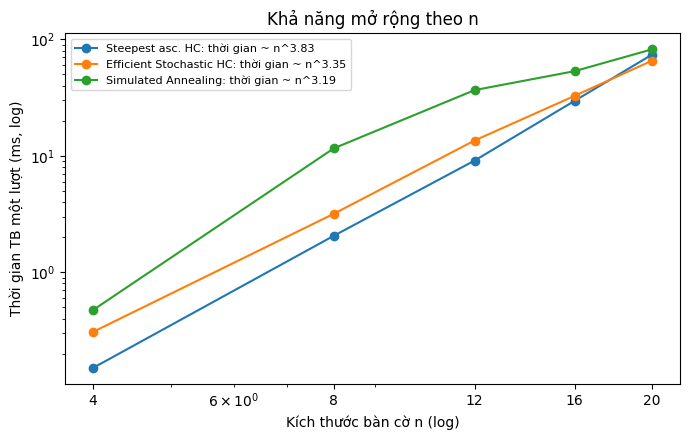

time_ms                                       \
Algorithm Efficient Stochastic HC Simulated Annealing Steepest asc. HC   
n                                                                        
4                             0.3                 0.5              0.2   
8                             3.2                11.6              2.1   
12                           13.5                36.6              9.1   
16                           32.6                53.2             29.6   
20                           65.5                81.9             73.8   

                            evals                                       \
Algorithm Efficient Stochastic HC Simulated Annealing Steepest asc. HC   
n                                                                        
4                            34.4                51.9             28.2   
8                           254.6               892.1            238.1   
12                          798.2              2176.3            713.8   
16                         1629.1              2583.0           1825.0   
20                         2756.7              3332.0           3535.0   

                          success                                       
Algorithm Efficient Stochastic HC Simulated Annealing Steepest asc. HC  
n                                                                       
4                            20.0               100.0             40.0  
8                            13.3                96.7             16.7  
12                            0.0                86.7             13.3  
16                            0.0                86.7              3.3  
20                            0.0                70.0              0.0

In [16]:
# Thời gian chạy theo n (một lượt đơn, KHÔNG restart), mỗi n chạy SCALE_RUNS lượt
SCALE_RUNS = 30
ns = [4, 8, 12, 16, 20]
scale_algos = {k: algorithms[k] for k in ("Steepest asc. HC", "Efficient Stochastic HC", "Simulated Annealing")}

scale_rows = []
for n in ns:
    np.random.seed(100 + n)
    boards = [random_board(n) for _ in range(SCALE_RUNS)]
    for name, algo in scale_algos.items():
        np.random.seed(0)
        df = run_many(algo, boards)
        scale_rows.append(dict(Algorithm=name, n=n, time_ms=df.time_ms.mean(),
                               evals=df.evals.mean(), success=100 * (df.h == 0).mean()))
scale_df = pd.DataFrame(scale_rows)

fig, ax = plt.subplots(figsize=(7, 4.5))
slopes = {}
for name, g in scale_df.groupby("Algorithm", sort=False):
    slope, _ = np.polyfit(np.log(g.n), np.log(g.time_ms), 1)   # time ~ n^slope
    slopes[name] = slope
    ax.loglog(g.n, g.time_ms, "o-", label=f"{name}: thời gian ~ n^{slope:.2f}")
ax.set_xticks(ns); ax.set_xticklabels(ns)
ax.set_xlabel("Kích thước bàn cờ n (log)"); ax.set_ylabel("Thời gian TB một lượt (ms, log)")
ax.set_title("Khả năng mở rộng theo n"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

scale_df.pivot(index="n", columns="Algorithm", values=["time_ms", "evals", "success"]).round(1)

**Nhận xét về khả năng mở rộng:**

Một lần gọi `conflicts()` tốn $O(n)$, và mỗi trạng thái có $N = n(n-1) \approx n^2$ láng giềng.

- **Steepest asc. HC, thực nghiệm ≈ $O(n^{3.83})$:**
  - Mỗi bước quét hết $n(n-1)$ láng giềng, mỗi láng giềng tốn $O(n)$, nên một bước tốn $O(n^3)$.
  - Số bước cũng tăng dần theo $n$, nên tổng ở khoảng $O(n^{3.5\text{–}4})$, khớp với số mũ đo được.
- **Efficient Stochastic HC, thực nghiệm ≈ $O(n^{3.35})$:**
  - Chi phí chủ yếu là `patience` $= N \ln N \approx 2n^2 \ln n$ lần thử ở cuối, mỗi lần $O(n)$. Tổng là $O(n^3 \log n)$, nên tăng chậm hơn Steepest.
- **Simulated Annealing, thực nghiệm ≈ $O(n^{3.19})$:**
  - Số mũ này **bị ảnh hưởng mạnh bởi cách cài đặt**: số vòng bị chặn ở `max_iters = 5000` và lịch $\alpha = 0{,}99$ được chỉnh cho n = 8.
  - Khi $n$ lớn, ngày càng nhiều lượt chạy hết 5000 vòng. Thời gian lúc đó chỉ còn tăng theo chi phí $O(n)$ của mỗi vòng (đường cong cong xuống ở n = 12–20), và tỷ lệ thành công giảm.
  - Nếu muốn giữ tỷ lệ thành công thì phải tăng `max_iters` và làm nguội chậm hơn theo $n$. Khi đó số mũ sẽ lớn hơn.
- **Thuật toán nào mở rộng tốt nhất?**
  - Xét riêng thời gian một lượt, ba thuật toán cùng bậc ($n^{3}$–$n^{4}$).
  - Nhưng khi $n$ lớn, Steepest và Efficient HC gần như **không còn tìm được nghiệm** (0% ở n = 20), nên phải dùng restart với số lần khởi động lại khoảng $1/p \to \infty$.
  - **SA là thuật toán mở rộng tốt nhất trên thực tế:** nó vẫn giải được phần lớn bài ở n = 20, với chi phí mỗi lượt có kiểm soát.
  - Trong nhóm HC, Efficient Stochastic tăng chậm nhất về thời gian, vì nó không phải quét $O(n^2)$ láng giềng ở mỗi bước.
- **Hạn chế của thí nghiệm:**
  - Chỉ có 5 giá trị $n$ và 30 lượt mỗi điểm.
  - Thời gian đo bằng Python thuần nên còn chịu chi phí trình thông dịch.
  - Số mũ ước lượng chỉ mang tính tương đối. Muốn so sánh chính xác hơn thì nên dùng số lần đánh giá (không phụ thuộc máy) hoặc tăng $n$ lớn hơn.

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

### Cài đặt các toán tử di chuyển

Mỗi toán tử nhận bàn cờ hiện tại và trả về **một bàn láng giềng mới**, không sửa bàn cũ. Hàm `stochastic_hc_op(board, move)` chính là Efficient Stochastic HC của Task 3, chỉ khác là toán tử di chuyển được truyền vào như một tham số.

| Toán tử | Cách sinh láng giềng | Số láng giềng (n = 8) |
|---|---|---|
| Original | dời 1 quân sang hàng bất kỳ khác | $n(n-1) = 56$ |
| Single-step | dời 1 quân lên/xuống đúng 1 ô | $\le 2n = 16$ |
| Column swap | đổi hàng của 2 quân ở 2 cột | $\binom{n}{2} = 28$ |
| Dual-queen | dời đồng thời 2 quân sang hàng mới | $\binom{n}{2}(n-1)^2 = 1372$ |
| Adaptive | tự chọn kiểu nước theo trạng thái (xem dưới) | thay đổi |

**Toán tử Adaptive (tự thiết kế)** dựa trên hai quan sát:
1. **Chỉ quân đang bị tấn công mới cần dời.** Hàm `queen_conflicts()` tính số quân tấn công từng quân trong $O(n)$. Adaptive chọn một quân với xác suất **tỷ lệ với số xung đột của nó**, nên quân bị tấn công nhiều được ưu tiên.
2. **Nước đi phù hợp phụ thuộc vào trạng thái bàn cờ:**
   - Nếu bàn còn **hàng trùng**, quân được chọn sẽ dời sang một **hàng đang trống**. Mỗi nước như vậy đưa bàn cờ tiến dần đến một hoán vị, tức không còn xung đột hàng.
   - Nếu bàn đã là **hoán vị** (mỗi hàng đúng 1 quân), Adaptive dùng **swap** giữa quân đó và một cột khác. Swap giữ nguyên tính hoán vị, nên chỉ còn phải sửa xung đột đường chéo.
   - Với xác suất $\varepsilon = 0{,}1$, Adaptive dùng toán tử gốc để không bị khóa trong một kiểu nước đi.

Để tính chi phí công bằng, mỗi lần thử một láng giềng tính là **1 lần đánh giá** `conflicts()` cho mọi toán tử. Chi phí $O(n)$ của `queen_conflicts()` trong Adaptive không được cộng vào số lần đánh giá, nhưng **có** được tính trong thời gian chạy.

In [17]:
# ---------- Các toán tử di chuyển cục bộ: nhận board, trả về board MỚI (không sửa board cũ) ----------

def move_original(board):
    """Toán tử gốc: dời một quân hậu sang một hàng bất kỳ khác trong cột của nó."""
    b = board.copy(); n = len(b)
    col = np.random.randint(n)
    row = np.random.randint(n - 1)
    b[col] = row + (row >= b[col])
    return b

def move_single_step(board):
    """Single-step: dời một quân hậu lên hoặc xuống đúng 1 ô (nếu chạm mép thì đi hướng còn lại)."""
    b = board.copy(); n = len(b)
    col = np.random.randint(n)
    step = 1 if np.random.rand() < 0.5 else -1
    if not 0 <= b[col] + step < n:
        step = -step
    b[col] += step
    return b

def move_swap(board):
    """Column swap: đổi hàng của hai quân hậu ở hai cột ngẫu nhiên khác nhau."""
    b = board.copy(); n = len(b)
    i, j = np.random.choice(n, 2, replace=False)
    b[i], b[j] = b[j], b[i]
    return b

def move_dual(board):
    """Dual-queen: chọn hai quân hậu và dời CẢ HAI sang hàng mới cùng lúc."""
    b = board.copy(); n = len(b)
    for col in np.random.choice(n, 2, replace=False):
        row = np.random.randint(n - 1)
        b[col] = row + (row >= b[col])
    return b

def queen_conflicts(board):
    """Số quân hậu khác đang tấn công từng quân (tính O(n) bằng cách đếm theo hàng và đường chéo)."""
    n = len(board); idx = np.arange(n)
    rows = np.bincount(board, minlength=n)
    d1 = np.bincount(idx + board, minlength=2 * n)
    d2 = np.bincount(idx - board + n, minlength=2 * n)
    return rows[board] + d1[idx + board] + d2[idx - board + n] - 3

def move_adaptive(board, eps=0.1):
    """Adaptive: chọn kiểu nước đi dựa trên trạng thái hiện tại.
    - Luôn tập trung vào quân ĐANG BỊ TẤN CÔNG (xác suất chọn tỷ lệ với số xung đột của quân).
    - Nếu bàn còn hàng trùng (chưa là hoán vị): dời quân đó sang một hàng ĐANG TRỐNG -> loại xung đột hàng.
    - Nếu bàn đã là hoán vị (không còn xung đột hàng): đổi chỗ quân đó với một cột khác (swap) -> vẫn giữ hoán vị.
    - Với xác suất eps dùng toán tử gốc để tránh bị khóa trong một kiểu nước đi."""
    n = len(board)
    qc = queen_conflicts(board)
    if qc.sum() == 0 or np.random.rand() < eps:
        return move_original(board)
    b = board.copy()
    col = np.random.choice(n, p=qc / qc.sum())
    empty_rows = np.setdiff1d(np.arange(n), b)
    if len(empty_rows) > 0:                              # còn hàng trống -> chưa phải hoán vị
        b[col] = empty_rows[np.random.randint(len(empty_rows))]
    else:                                                # hoán vị -> swap với cột khác
        other = np.random.randint(n - 1)
        other += other >= col
        b[col], b[other] = b[other], b[col]
    return b

def stochastic_hc_op(board, move, patience=None, max_iters=20000):
    """Efficient Stochastic HC (Task 3) nhưng nhận toán tử di chuyển `move` làm tham số."""
    board = np.array(board).copy()
    n = len(board)
    if patience is None:
        patience = default_patience(n)                   # cùng patience cho mọi toán tử -> so sánh công bằng
    h = conflicts(board)
    evals, steps, fails, it, history = 1, 0, 0, 0, [h]
    while h > 0 and fails < patience and it < max_iters:
        it += 1
        cand = move(board)
        nh = conflicts(cand); evals += 1
        if nh < h:
            board, h, steps, fails = cand, nh, steps + 1, 0
        else:
            fails += 1
        history.append(h)
    return board, dict(conflicts=h, steps=steps, evals=evals, history=history)


operators = {"Original (1 quân, hàng bất kỳ)": move_original,
             "Single-step (±1 ô)":             move_single_step,
             "Column swap":                    move_swap,
             "Dual-queen":                     move_dual,
             "Adaptive":                       move_adaptive}

# Kiểm tra nhanh: mọi toán tử giữ đúng dạng bàn cờ và không sửa bàn cờ đầu vào
np.random.seed(0)
_b = random_board(8)
for name, op in operators.items():
    _c = _b.copy(); _new = op(_c)
    assert (_c == _b).all() and len(_new) == 8 and _new.min() >= 0 and _new.max() < 8
assert all(queen_conflicts(b).sum() == 2 * conflicts(b) for b in (random_board(12) for _ in range(200)))
print("Các toán tử hợp lệ; tổng xung đột theo từng quân = 2 x conflicts() (mỗi cặp được đếm 2 lần).")

Các toán tử hợp lệ; tổng xung đột theo từng quân = 2 x conflicts() (mỗi cặp được đếm 2 lần).


### Thí nghiệm

- **Thiết lập chạy:** Efficient Stochastic HC chạy với từng toán tử, **100 lượt** cho mỗi n = 8 và n = 12.
  - 100 bàn khởi tạo được sinh một lần (`seed = 123`) và dùng chung cho mọi toán tử.
  - Mọi toán tử dùng **cùng điều kiện dừng**: $h = 0$, hoặc `patience = ⌈N ln N⌉` lần thử thất bại liên tiếp với $N = n(n-1)$ như Task 3, hoặc tối đa 20000 vòng.
  - Giữ cùng `patience` nghĩa là cho mọi toán tử cùng một "ngân sách kiên nhẫn", để so sánh công bằng.
- **Thí nghiệm bổ sung "Column swap (khởi tạo hoán vị)":** swap không bao giờ thay đổi *tập* các hàng đang dùng. Vì vậy nếu bàn khởi tạo có hai quân cùng hàng thì swap **không thể** sửa được xung đột hàng đó. Để kiểm tra nhận định này, ta chạy thêm swap từ bàn khởi tạo là một **hoán vị ngẫu nhiên** (`np.random.permutation(n)`).
- **Lưu kết quả:** mỗi lượt lưu $h$ cuối, số lần đánh giá, thời gian, và toàn bộ lịch sử $h$ để vẽ đường trung bình.

In [18]:
ADV_RUNS = 100
adv_runs, adv_hist = {}, {}
for n in (8, 12):
    np.random.seed(123)
    boards = [random_board(n) for _ in range(ADV_RUNS)]              # dùng chung cho mọi toán tử
    perm_boards = [np.random.permutation(n) for _ in range(ADV_RUNS)]  # cho thí nghiệm swap từ hoán vị
    setups = {name: (op, boards) for name, op in operators.items()}
    setups["Column swap (khởi tạo hoán vị)"] = (move_swap, perm_boards)
    for name, (op, starts) in setups.items():
        np.random.seed(0)
        rows, hists = [], []
        for b in starts:
            t0 = time.perf_counter()
            _, info = stochastic_hc_op(b, op)
            rows.append(dict(h=info['conflicts'], evals=info['evals'],
                             time_ms=1000 * (time.perf_counter() - t0)))
            hists.append(info['history'])
        adv_runs[(name, n)] = pd.DataFrame(rows)
        adv_hist[(name, n)] = hists

adv_table = pd.DataFrame([{"Toán tử": name, "n": n,
                           "Thành công (%)": 100 * (df.h == 0).mean(),
                           "h cuối TB": df.h.mean(),
                           "Số lần đánh giá TB": df.evals.mean(),
                           "Thời gian TB (ms)": df.time_ms.mean(),
                           "Thời gian TB khi thành công (ms)": df.time_ms[df.h == 0].mean()}
                          for (name, n), df in adv_runs.items()])
adv_table.round(2)

,Toán tử,n,Thành công (%),h cuối TB,Số lần đánh giá TB,Thời gian TB (ms),Thời gian TB khi thành công (ms)
0,"Original (1 quân, hàng bất kỳ)",8,15.0,1.21,254.61,3.62,0.96
1,Single-step (±1 ô),8,0.0,3.69,248.42,2.86,NaN
2,Column swap,8,0.0,4.60,246.76,4.10,NaN
3,Dual-queen,8,2.0,1.49,317.93,8.20,1.98
4,Adaptive,8,38.0,0.83,160.42,10.42,1.46
5,Column swap (khởi tạo hoán vị),8,40.0,0.66,162.25,2.94,0.65
6,"Original (1 quân, hàng bất kỳ)",12,2.0,1.91,807.07,14.64,3.65
7,Single-step (±1 ô),12,0.0,5.50,683.55,10.54,NaN
8,Column swap,12,0.0,6.63,705.74,14.57,NaN
9,Dual-queen,12,1.0,1.81,954.19,27.56,33.99


Ba biểu đồ dưới đây vẽ cho từng toán tử, ở cả n = 8 và n = 12:
1. **Chất lượng nghiệm trung bình theo vòng lặp.** Lượt nào đã dừng thì giữ nguyên $h$ cuối của nó cho các vòng sau.
2. **Phân bố $h$ cuối** của 100 lượt.
3. **Thời gian trung bình tới nghiệm**, chỉ tính các lượt thành công. Tỷ lệ thành công được ghi trên mỗi cột.

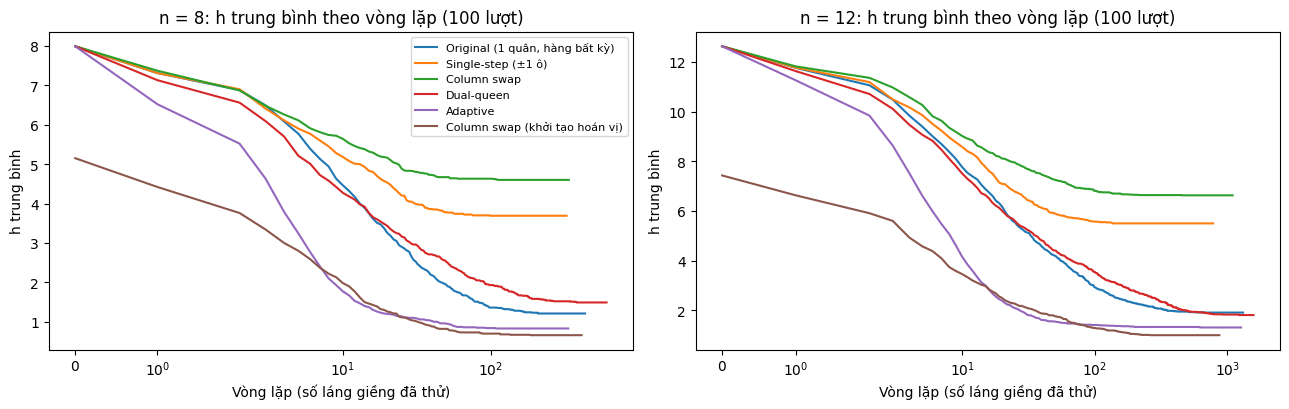

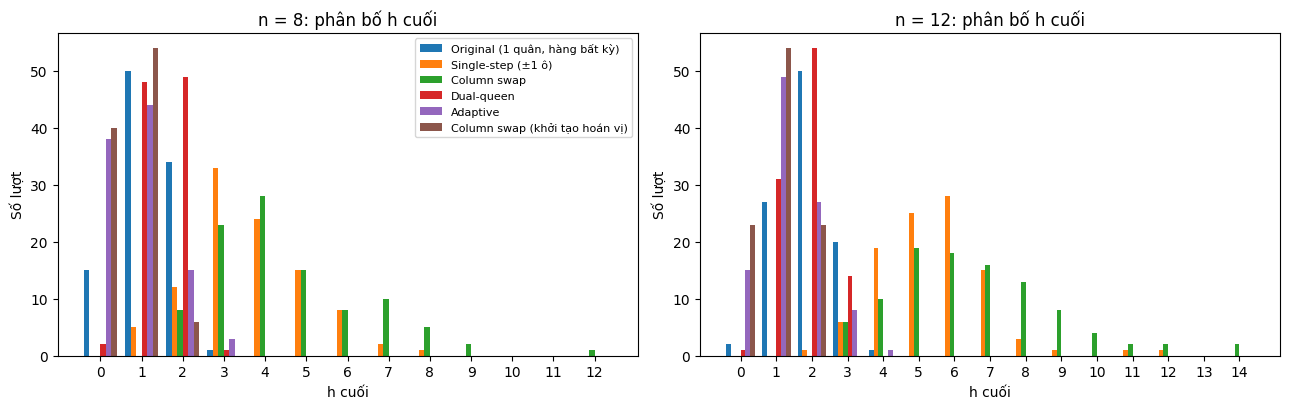

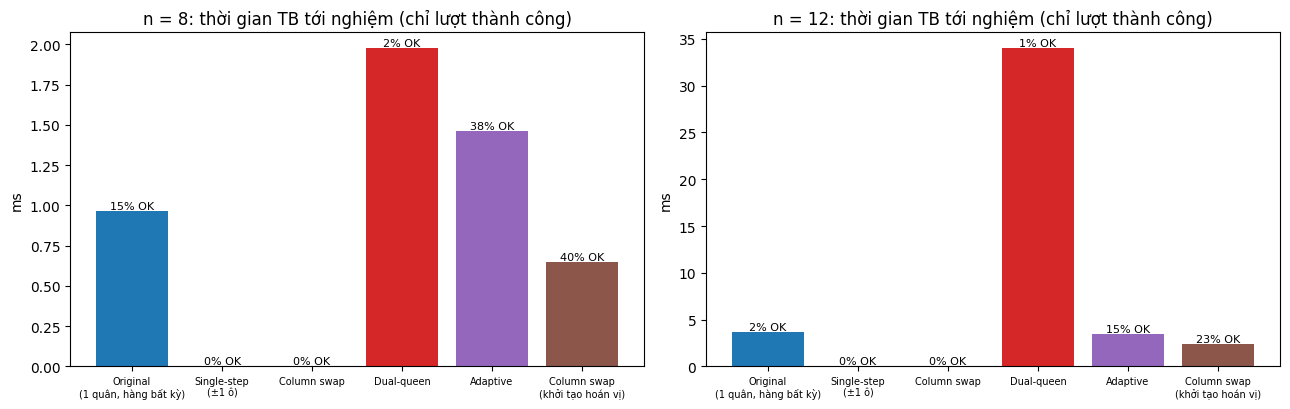

In [19]:
op_names = list(dict.fromkeys(name for name, _ in adv_runs))
colors_op = dict(zip(op_names, plt.cm.tab10.colors))

def mean_curve(hists):
    """Trung bình h theo vòng lặp; lượt đã dừng thì giữ nguyên h cuối của nó cho các vòng sau."""
    L = max(len(h) for h in hists)
    return np.array([np.pad(h, (0, L - len(h)), mode="edge") for h in hists]).mean(axis=0)

# (1) Chất lượng nghiệm trung bình theo vòng lặp
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, n in zip(axes, (8, 12)):
    for name in op_names:
        ax.plot(mean_curve(adv_hist[(name, n)]), label=name, color=colors_op[name])
    ax.set_xscale("symlog"); ax.set_xlabel("Vòng lặp (số láng giềng đã thử)"); ax.set_ylabel("h trung bình")
    ax.set_title(f"n = {n}: h trung bình theo vòng lặp ({ADV_RUNS} lượt)")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# (2) Phân bố h cuối
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, n in zip(axes, (8, 12)):
    max_h = max(adv_runs[(name, n)].h.max() for name in op_names)
    xs = np.arange(max_h + 1); w = 0.8 / len(op_names)
    for k, name in enumerate(op_names):
        counts = np.bincount(adv_runs[(name, n)].h, minlength=max_h + 1)
        ax.bar(xs + (k - (len(op_names) - 1) / 2) * w, counts, w, label=name, color=colors_op[name])
    ax.set_xticks(xs); ax.set_xlabel("h cuối"); ax.set_ylabel("Số lượt")
    ax.set_title(f"n = {n}: phân bố h cuối")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# (3) Thời gian trung bình tới nghiệm của các lượt thành công (ghi kèm tỷ lệ thành công)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, n in zip(axes, (8, 12)):
    sub = adv_table[adv_table.n == n].set_index("Toán tử").loc[op_names]
    t = sub["Thời gian TB khi thành công (ms)"].fillna(0)
    bars = ax.bar(range(len(op_names)), t, color=[colors_op[s] for s in op_names])
    for bar, p, tt in zip(bars, sub["Thành công (%)"], t):
        ax.text(bar.get_x() + bar.get_width() / 2, tt, f"{p:.0f}% OK" if p > 0 else "0% OK",
                ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(op_names)))
    ax.set_xticklabels([s.replace(" (", "\n(") for s in op_names], fontsize=7)
    ax.set_ylabel("ms"); ax.set_title(f"n = {n}: thời gian TB tới nghiệm (chỉ lượt thành công)")
plt.tight_layout(); plt.show()

### Thảo luận

**Kết quả chính (100 lượt mỗi toán tử, Efficient Stochastic HC, cùng `patience`):**

| Toán tử | Thành công n = 8 | h cuối TB n = 8 | Thành công n = 12 | h cuối TB n = 12 |
|---|---|---|---|---|
| Original | 15% | 1,21 | 2% | 1,91 |
| Single-step | 0% | 3,69 | 0% | 5,50 |
| Column swap (bàn ngẫu nhiên) | 0% | 4,60 | 0% | 6,63 |
| Dual-queen | 2% | 1,49 | 1% | 1,81 |
| **Adaptive** | **38%** | 0,83 | **15%** | 1,31 |
| **Column swap (khởi tạo hoán vị)** | **40%** | 0,66 | **23%** | 1,00 |

**Những gì học được:**

- **Single-step kém nhất về chất lượng.** Mỗi quân chỉ có tối đa 2 láng giềng, nên lân cận rất hẹp. Một quân muốn sang hàng xa thì phải đi qua các hàng trung gian, và thường có một hàng trung gian làm $h$ tăng, mà HC lại không chấp nhận nước tệ hơn. Vì vậy thuật toán kẹt rất sớm ($h$ TB = 3,7 ở n = 8; 5,5 ở n = 12). Toán tử này chỉ hợp khi cần tinh chỉnh nhỏ quanh một nghiệm gần đúng, hoặc khi dùng cùng SA.
- **Column swap phụ thuộc hoàn toàn vào bàn khởi tạo.** Swap không đổi *tập* hàng đang dùng. Từ bàn ngẫu nhiên có hàng trùng, nó **không bao giờ** sửa được xung đột hàng, nên thành công 0% và $h$ cao nhất. Khi khởi tạo là **hoán vị**, không gian tìm kiếm chỉ còn các hoán vị: không có xung đột hàng, $h$ ban đầu đã thấp hơn hẳn (đường nâu bắt đầu thấp nhất ở biểu đồ 1), và mỗi swap giữ nguyên tính hoán vị. Đây là **toán tử tốt nhất** trong thí nghiệm (40% ở n = 8, 23% ở n = 12) với thời gian tới nghiệm thấp nhất. Bài học: toán tử và cách biểu diễn hoặc khởi tạo phải đi cùng nhau.
- **Dual-queen có quá nhiều láng giềng.** Ở n = 8 có 1372 láng giềng, gấp khoảng 25 lần toán tử gốc. Dời cùng lúc hai quân thường phá hỏng một quân đang tốt, nên tỷ lệ nước cải thiện rất thấp. Với cùng `patience`, thuật toán dừng trước khi tìm được nước cải thiện hiếm hoi. Do đó $h$ cuối gần bằng Original nhưng gần như không bao giờ đạt 0 (1–2%). Ngoài ra, thời gian tới nghiệm của Dual-queen chỉ tính trên 1–2 lượt thành công nên không đáng tin về mặt thống kê.
- **Adaptive cải thiện rõ so với Original** (38% so với 15% ở n = 8; 15% so với 2% ở n = 12). Lý do:
  - Nó chỉ dời quân đang bị tấn công, nên không phí lượt thử vào quân đã ổn.
  - Nó dời sang hàng trống, nên nhanh chóng loại hết xung đột hàng.
  - Khi bàn đã là hoán vị, nó chuyển sang swap, tức tự động "chuyển" sang toán tử tốt nhất.
  - Trên biểu đồ 1, đường tím giảm nhanh nhất trong khoảng 5–20 vòng đầu.
  - Nhược điểm: mỗi lần thử phải tính `queen_conflicts()` và gọi `np.random.choice` với phân phối xác suất. Vì vậy thời gian TB **mỗi lượt** cao hơn (khoảng 10 ms so với 3,6 ms ở n = 8), dù số lần đánh giá ít hơn.
- **Chi phí để có một nghiệm** ≈ thời gian TB một lượt / tỷ lệ thành công (khi kết hợp với random restart):
  - n = 8: Original ≈ 24 ms, Adaptive ≈ 27 ms, Swap từ hoán vị ≈ 7 ms.
  - n = 12: Original ≈ 730 ms, Adaptive ≈ 250 ms, Swap từ hoán vị ≈ 53 ms.
  - Như vậy ở bàn nhỏ, chi phí phụ của Adaptive bù trừ phần lợi ích. Ở bàn lớn hơn thì Adaptive và swap từ hoán vị vượt trội.

**Kết luận chọn toán tử:**
- Bàn khởi tạo là hoán vị: dùng **Column swap**.
- Bàn khởi tạo bất kỳ: dùng **Adaptive**, vì nó tự đưa bàn về hoán vị rồi chuyển sang swap.
- Original: là lựa chọn mặc định đơn giản.
- Single-step và Dual-queen: không phù hợp với hill climbing chỉ nhận nước cải thiện.

**Hạn chế:**
- Chỉ có 100 lượt mỗi thiết lập, nên các khác biệt nhỏ (ví dụ 38% so với 40%) nằm trong sai số thống kê.
- Mọi toán tử dùng cùng một `patience`, mà giá trị này được chọn cho toán tử gốc. Nếu chỉnh `patience` riêng theo kích thước lân cận của từng toán tử, Dual-queen có thể tốt hơn.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [20]:
# Code and description go here